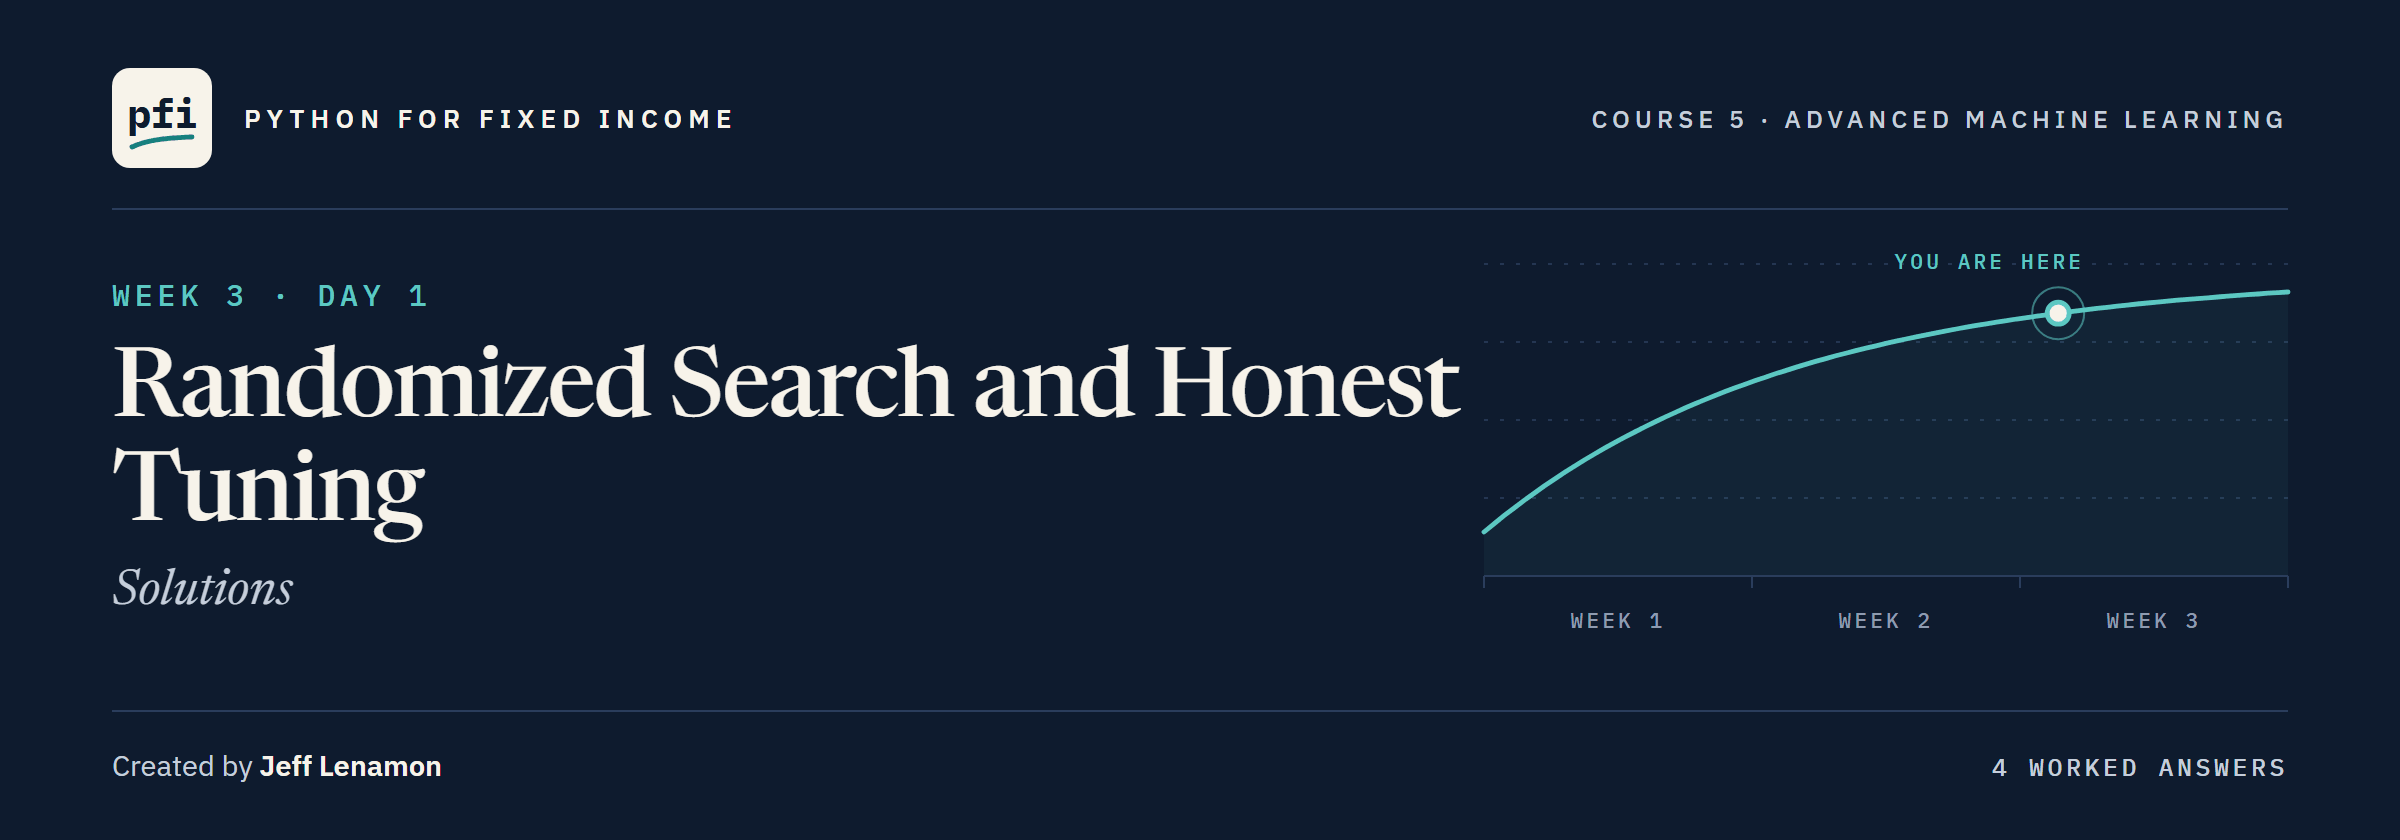

# Randomized Search and Honest Tuning: Solutions

Week 3, Day 1. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `polish_bankruptcy_5year.csv`, 5,910 financial statements of Polish companies: **real**, UCI Machine Learning Repository dataset 365, CC BY 4.0. Citation: Tomczak, S. (2016). Polish Companies Bankruptcy [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5F600.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week3/day1/11_randomized_search_and_honest_tuning_solutions.ipynb)

# Problem Statement

## Business Context

In Course 4's capstone a colleague who covers emerging market corporates handed the desk a public file: financial statements of Polish companies, and a flag for the ones that went bankrupt within a year.
The dataset page says the bankrupt companies were analysed from 2000 to 2012 and the ones still operating from 2007 to 2013 ([dataset page](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data)), so it is one country in one period.
Course 4 chose a logistic regression on it, at a fold average precision of 0.6624.
After two weeks of boosting she is back with three questions: does a booster rank these companies better, does tuning it help, and how much of a tuned score can she believe?
A model's output here is the model's probability of bankruptcy in this file, never a credit view on any company.

## Objectives

Score a booster on five folds of the training rows, and count what a grid of settings costs.
Search two settings with a grid, with `RandomizedSearchCV` and with an Optuna study on one budget, and read a search's results fold by fold.
Measure how far reshuffling the folds alone moves a score, score a search with nested cross-validation, and choose a threshold for a recall after the search.

## Data Dictionary

`polish_bankruptcy_5year.csv`, one row per financial statement:

1. `Attr1` to `Attr64`: the 64 features, the page's X1 to X64 in order, mostly ratios from the statements: nine are in days, X29 is a logarithm of total assets, and X55 is working capital, an amount
2. `class`: 1 if the company went bankrupt within a year, **the target**

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split and fold the rows, score by folds, and search settings
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.model_selection import cross_val_predict, GridSearchCV, RandomizedSearchCV
from scipy.stats import randint, loguniform

# Course 4's logistic pipeline, and the booster
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier

# to choose a threshold and score the flags
from sklearn.metrics import precision_recall_curve, precision_score

# the guided search, kept quiet: otherwise it writes a line for every trial
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

# Loading the Data

## Reading the File

In [3]:
# the 5,910 statements: 64 features named Attr1 to Attr64, and the outcome in class
bankrupt = pd.read_csv(DATA + "polish_bankruptcy_5year.csv")
TARGET = "class"
FEATURES = [column for column in bankrupt.columns if column != TARGET]
print(len(bankrupt), "statements,", len(FEATURES), "features")

5910 statements, 64 features


## Rebuilding Course 4's Rows

In [4]:
# Course 4's capstone: the exact copies out, then one stratified 80/20 split with the course seed
unique = bankrupt.drop_duplicates()
X, y = unique[FEATURES], unique[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(len(unique), "unique rows,", y.sum(), "bankrupt")
print("Training:", len(X_train), "rows,", y_train.sum(), "bankrupt.  Test:", len(X_test), "rows,", y_test.sum(), "bankrupt")

5850 unique rows, 408 bankrupt
Training: 4680 rows, 326 bankrupt.  Test: 1170 rows, 82 bankrupt


The same 4,680 training rows as Course 4's capstone.

The 1,170 test rows are never scored in Course 5.

![The Polish file's rows, drawn to scale. 5,910 statements are read and 60 exact copies dropped, leaving 5,850. One stratified split with the course seed gives 4,680 training rows, 326 bankrupt, cut into five folds of 936 that fit, search and score every model today, and 1,170 test rows, 82 bankrupt, behind a dashed edge: never scored in Course 5.](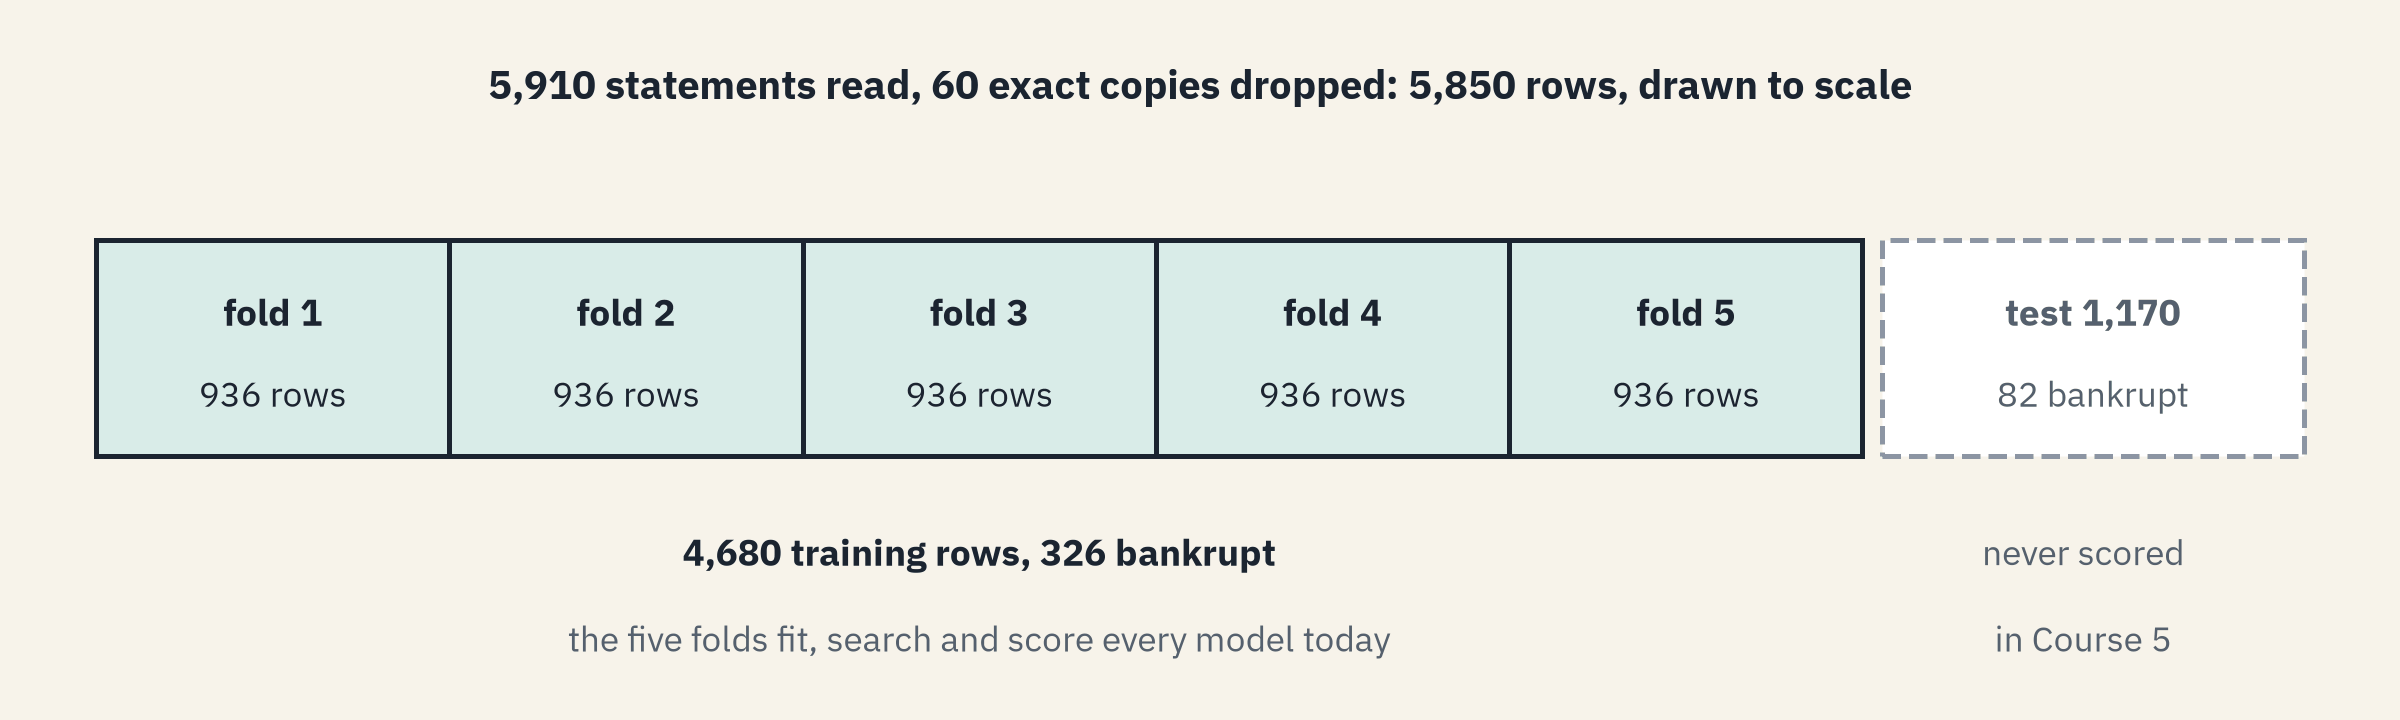)

## Five Folds for Every Search

In [5]:
# five stratified folds of the training rows, shuffled with the course seed: every score today uses them
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

**Every search today is scored on the same five folds of the 4,680; the test rows stay closed.**

# Data Overview

## The Rare Class and the Gaps

In [6]:
# the bankrupt share, and each column's share missing in percent, gappiest first
missing = X_train.isna().mean().sort_values(ascending=False) * 100
print("Bankrupt:", round(y_train.mean() * 100, 2), "percent")
print("Columns with a gap:", (missing > 0).sum(), " Companies with at least one:", X_train.isna().any(axis=1).sum())

Bankrupt: 6.97 percent
Columns with a gap: 48  Companies with at least one: 2248


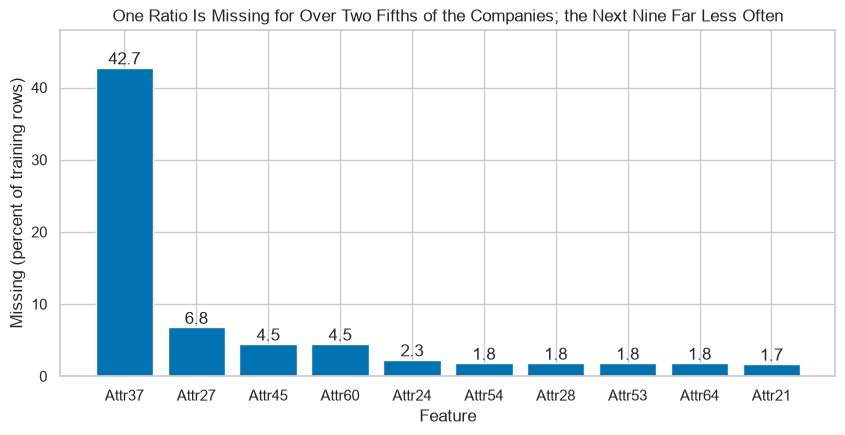

In [7]:
# the ten gappiest columns as bars, each labelled with its share
plt.figure(figsize=(10, 4.5))
bars = plt.bar(missing.index[:10], missing.values[:10])
plt.bar_label(bars, fmt="%.1f")
plt.ylim(0, 48)
plt.xlabel("Feature")
plt.ylabel("Missing (percent of training rows)")
plt.title("One Ratio Is Missing for Over Two Fifths of the Companies; the Next Nine Far Less Often")
plt.show()

Course 4's capstone explored this file in full and filled the gaps with medians and missing indicators.

With 6.97 percent bankrupt, a ranking in random order scores about 0.07 in average precision, the yardstick today.

**LightGBM learns at each split which side the gaps go to, so the rows go in as they are, with no imputer.**

# Model Building

## Course 4's Choice, on the Same Folds

In [8]:
# Course 4's chosen pipeline: medians and missing indicators, normal scores, a balanced logistic regression
logistic = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                     ("quantile", QuantileTransformer(output_distribution="normal", random_state=SEED)),
                     ("logit", LogisticRegression(solver="newton-cholesky", tol=1e-8, class_weight="balanced"))])

# its average precision on each of the five folds
logistic_cv = cross_validate(logistic, X_train, y_train, cv=folds, scoring="average_precision", n_jobs=1)
print("Folds:", logistic_cv["test_score"].round(4), " Mean:", round(logistic_cv["test_score"].mean(), 4))

Folds: [0.5381 0.7195 0.6186 0.675  0.7607]  Mean: 0.6624


The same 0.6624 the capstone reported, now fold by fold.

**Predict 1**

Q. Day 9's `LGBMClassifier`, untouched, on the same five folds. Write down its fold average precision.

## LightGBM at Its Defaults

In [9]:
# Day 9's booster at its defaults: the course seed, one thread, and no log
default = LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1)
params = default.get_params()
print({name: params[name] for name in ["n_estimators", "num_leaves", "learning_rate", "min_child_samples"]})

{'n_estimators': 100, 'num_leaves': 31, 'learning_rate': 0.1, 'min_child_samples': 20}


In [10]:
# each fold scored, and the rows each fold's model was fitted on (Day 5's fitted folds)
default_cv = cross_validate(default, X_train, y_train, cv=folds, scoring="average_precision", return_train_score=True, n_jobs=1)
default_scores = default_cv["test_score"]
print("Folds:", default_scores.round(4))
print("Mean:", round(default_scores.mean(), 4), " Fold sd:", round(default_scores.std(), 4), " Fitted folds:", round(default_cv["train_score"].mean(), 4))

Folds: [0.7077 0.7988 0.7434 0.8013 0.8405]
Mean: 0.7783  Fold sd: 0.0469  Fitted folds: 1.0


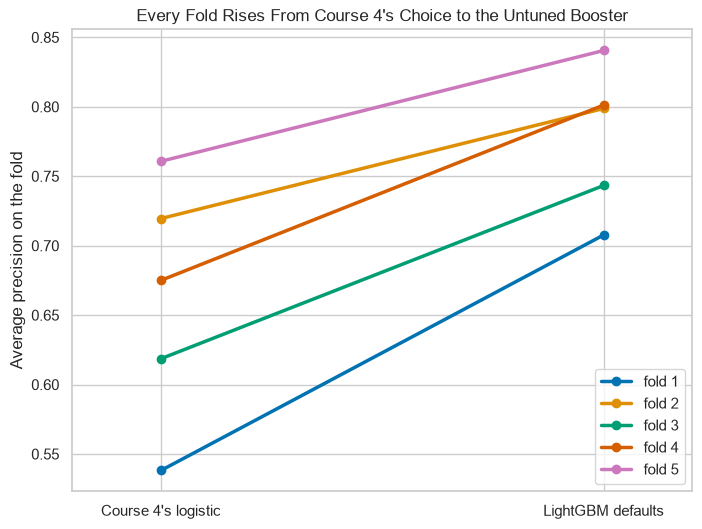

In [11]:
# one line per fold: Course 4's logistic on the left, the untuned booster on the right
pair = pd.DataFrame({"Course 4's logistic": logistic_cv["test_score"], "LightGBM defaults": default_scores}, index=range(1, 6))
plt.figure(figsize=(8, 6))
for fold, row in pair.iterrows():
    plt.plot([0, 1], row.values, marker="o", linewidth=2.5, label="fold " + str(fold))
plt.xticks([0, 1], pair.columns)
plt.xlim(-0.2, 1.2)
plt.ylabel("Average precision on the fold")
plt.title("Every Fold Rises From Course 4's Choice to the Untuned Booster")
plt.legend(loc="lower right")
plt.show()

Every fold rises, by 0.08 to 0.17, and fold 1 is the hardest fold for both models.

On the rows it was fitted on, the booster scores 1.0: it memorises them, and still ranks unseen companies far better.

**The booster ranks unseen companies far better than Course 4's choice, untuned. The question is whether tuning adds anything.**

# What a Grid Costs

## Settings Worth Searching

Day 9 measured three LightGBM settings one at a time: `num_leaves`, `learning_rate` and `min_child_samples`.
Today searches the first two, so every search fits on one page.
A **search space** is the settings to search and the values each may take; a **candidate** is one combination of values, scored on every fold.

## Candidates Times Folds

In [12]:
# a grid tries every combination: four values of each of six settings, each candidate scored on five folds
candidates = 4 ** 6
print("Candidates:", candidates, " Fits:", candidates * 5)

Candidates: 4096  Fits: 20480


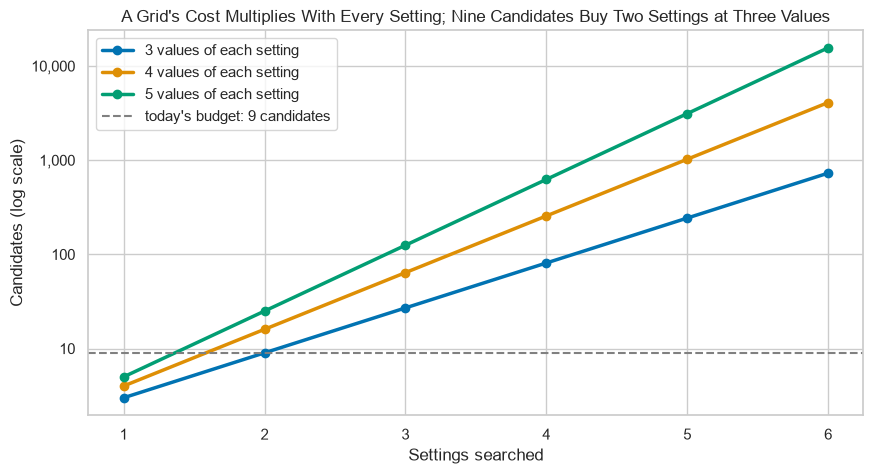

In [13]:
# candidates against the number of settings, for 3, 4 and 5 values of each, on a log axis
settings = np.arange(1, 7)
for values in [3, 4, 5]:
    plt.plot(settings, values ** settings, marker="o", linewidth=2.5, label=str(values) + " values of each setting")
plt.axhline(9, color="gray", linestyle="--", label="today's budget: 9 candidates")
plt.yscale("log")
plt.yticks([10, 100, 1000, 10000], ["10", "100", "1,000", "10,000"])
plt.xlabel("Settings searched")
plt.ylabel("Candidates (log scale)")
plt.title("A Grid's Cost Multiplies With Every Setting; Nine Candidates Buy Two Settings at Three Values")
plt.legend(loc="upper left")
plt.show()

Each setting added multiplies the candidates by its number of values.

Six settings at four values each cost 4,096 candidates, 20,480 fits.

**The budget is fixed before any search: nine candidates, 45 fits, for every search today.**

# Three Ways to Spend Nine Candidates

## The Grid

In [14]:
# a grid like Day 10's: three leaf counts by three learning rates, here on the Polish folds
grid = GridSearchCV(LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1),
                    {"num_leaves": [8, 16, 31], "learning_rate": [0.03, 0.1, 0.3]},
                    cv=folds, scoring="average_precision", n_jobs=1).fit(X_train, y_train)

# each candidate's fold mean, leaves down and rates across
grid_table = pd.DataFrame(grid.cv_results_["params"])
grid_table["mean"] = grid.cv_results_["mean_test_score"]
grid_table.pivot(index="num_leaves", columns="learning_rate", values="mean")

learning_rate,0.0300,0.1000,0.3000
num_leaves,,,
8,0.7530,0.7737,0.7715
16,0.7644,0.7758,0.7729
31,0.7622,0.7783,0.7697


The best cell is 31 leaves at a rate of 0.1, the defaults' own cell, at 0.7783.

The other eight score 0.7530 to 0.7758.

## Drawing Settings at Random

A **randomized search** draws each candidate's values from a **distribution** for each setting, instead of a list.
`randint(8, 32)` draws a whole number from 8 to 31, each equally likely.
`loguniform(0.03, 0.3)` draws a rate as likely between 0.03 and 0.06 as between 0.15 and 0.3, since each doubles the rate: even on a log scale, so it is called **log-uniform**.
`.rvs(size=, random_state=)` draws from a distribution.

In [15]:
# 1,000 draws from each distribution, seeded
leaf_draws = randint(8, 32).rvs(size=1000, random_state=SEED)
rate_draws = loguniform(0.03, 0.3).rvs(size=1000, random_state=SEED)
print("Leaves:", leaf_draws.min(), "to", leaf_draws.max(), " Rates below 0.1:", (rate_draws < 0.1).sum(), "of 1000")

Leaves: 8 to 31  Rates below 0.1: 530 of 1000


`np.geomspace(0.03, 0.3, 31)` gives 31 points evenly spaced on a log scale, the bin edges for the last panel.
`RATE_TICKS` labels a log axis of rates in plain numbers; the searches' charts below use it too.

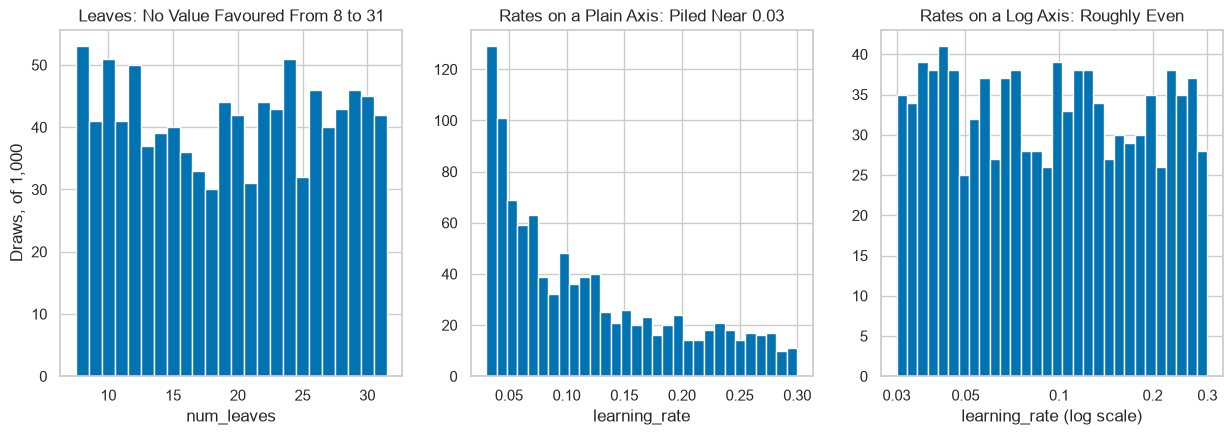

In [16]:
# plain labels for a log axis of rates
RATE_TICKS = [0.03, 0.05, 0.1, 0.2, 0.3]

# the draws as histograms: leaves, then the rates on a plain and on a log axis
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].hist(leaf_draws, bins=np.arange(7.5, 32.5, 1))
axes[0].set(xlabel="num_leaves", ylabel="Draws, of 1,000", title="Leaves: No Value Favoured From 8 to 31")
axes[1].hist(rate_draws, bins=30)
axes[1].set(xlabel="learning_rate", title="Rates on a Plain Axis: Piled Near 0.03")
axes[2].hist(rate_draws, bins=np.geomspace(0.03, 0.3, 31))
axes[2].set(xscale="log", xticks=RATE_TICKS, xticklabels=RATE_TICKS, xlabel="learning_rate (log scale)", title="Rates on a Log Axis: Roughly Even")
axes[2].minorticks_off()
plt.show()

Each leaf count from 8 to 31 is drawn about 40 times in 1,000.

About half the rates fall below 0.1, only a quarter of the way along the plain axis: small rates get as many tries as large ones.

**Predict 2**

The grid's best was 0.7783.

Q. The same budget of nine candidates, drawn at random from those two distributions. Write down the best fold mean.

## RandomizedSearchCV

`RandomizedSearchCV` takes the distributions as `param_distributions` and the number of candidates to draw as `n_iter`; `random_state=SEED` fixes the draws.

In [17]:
# the same model, folds and budget: nine candidates drawn from the two distributions
space = {"num_leaves": randint(8, 32), "learning_rate": loguniform(0.03, 0.3)}
search = RandomizedSearchCV(LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1), space, n_iter=9,
                            cv=folds, scoring="average_precision", random_state=SEED, n_jobs=1).fit(X_train, y_train)
print("Best:", search.best_params_["num_leaves"], "leaves, rate", round(search.best_params_["learning_rate"], 4), " Mean:", round(search.best_score_, 4))
print("Above the defaults by:", round(search.best_score_ - default_scores.mean(), 4))

Best: 28 leaves, rate 0.1619  Mean: 0.7811
Above the defaults by: 0.0027


The best draw beats the defaults by 0.0027, less than a tenth of the defaults' fold sd of 0.0469.

## A Guided Search With Optuna

Optuna is a library for searching settings.
It runs a **study**, a set of **trials**, each trial one candidate.
You write an **objective**, a function that takes a trial, asks it for values, and returns the score to maximise.
`trial.suggest_int("num_leaves", 8, 31)` and `trial.suggest_float("learning_rate", 0.03, 0.3, log=True)` ask for the same two distributions as above.

In [18]:
# the objective: one trial's values, scored on the same folds
def objective(trial):
    num_leaves = trial.suggest_int("num_leaves", 8, 31)
    learning_rate = trial.suggest_float("learning_rate", 0.03, 0.3, log=True)
    model = LGBMClassifier(num_leaves=num_leaves, learning_rate=learning_rate, random_state=SEED, n_jobs=1, verbose=-1)
    return cross_val_score(model, X_train, y_train, cv=folds, scoring="average_precision", n_jobs=1).mean()

`TPESampler(seed=SEED, n_startup_trials=4)` draws the first four trials at random, then places each next one where the trials so far scored best: a **guided search**.

In [19]:
# a seeded study: four random trials, then five guided ones, nine in all
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=4))
study.optimize(objective, n_trials=9)
print("Best:", study.best_params["num_leaves"], "leaves, rate", round(study.best_params["learning_rate"], 4), " Mean:", round(study.best_value, 4))
print("Above the defaults by:", round(study.best_value - default_scores.mean(), 4))

Best: 30 leaves, rate 0.2169  Mean: 0.7832
Above the defaults by: 0.0049


In [20]:
# each trial's values and score, from the study's own table
trials = study.trials_dataframe()[["number", "params_num_leaves", "params_learning_rate", "value"]]
trials

,number,params_num_leaves,params_learning_rate,value
0,0,16,0.2678,0.7769
1,1,25,0.1191,0.7775
2,2,11,0.0430,0.7725
3,3,9,0.2204,0.7682
4,4,31,0.1414,0.7796
5,5,30,0.0594,0.7661
6,6,22,0.0667,0.7782
7,7,30,0.2169,0.7832
8,8,17,0.1058,0.7798


The best is trial 7, a guided one, 0.0049 above the defaults.

Three of the five guided trials, numbers 4 to 8, sit at 30 or 31 leaves.

## Where Each Search Looked

In [21]:
# every candidate the three searches tried, in the order tried, with its fold mean
tried = pd.concat([
    pd.DataFrame(grid.cv_results_["params"]).assign(score=grid.cv_results_["mean_test_score"], search="Grid"),
    pd.DataFrame(search.cv_results_["params"]).assign(score=search.cv_results_["mean_test_score"], search="Random"),
    trials.rename(columns={"params_num_leaves": "num_leaves", "params_learning_rate": "learning_rate", "value": "score"})
          .drop(columns="number").assign(search="Optuna")], ignore_index=True)
tried["order"] = tried.groupby("search").cumcount() + 1

In [22]:
# one panel per search: a dot per candidate coloured by its fold mean, the best ringed, the defaults a cross,
# and a tick on each axis for every value tried (a rug)
def panels(tried_up_to, axes):
    for ax, name in zip(axes, ["Grid", "Random", "Optuna"]):
        rows = tried[(tried["search"] == name) & (tried["order"] <= tried_up_to)]
        dots = ax.scatter(rows["num_leaves"], rows["learning_rate"], c=rows["score"], cmap="viridis", vmin=0.75, vmax=0.785, s=160, edgecolor="black")
        best = rows.loc[rows["score"].idxmax()]
        ax.scatter(best["num_leaves"], best["learning_rate"], s=500, facecolor="none", edgecolor="C3", linewidth=2.5)
        ax.scatter(31, 0.1, marker="x", s=160, color="black")
        ax.scatter(rows["num_leaves"], [0.025] * len(rows), marker="|", s=300, color="gray")
        ax.scatter([5.6] * len(rows), rows["learning_rate"], marker="_", s=300, color="gray")
        ax.set(xlim=(5, 33), ylim=(0.024, 0.34), yscale="log", yticks=RATE_TICKS, yticklabels=RATE_TICKS, xlabel="num_leaves", title=name)
        ax.minorticks_off()
    axes[0].set_ylabel("learning_rate (log scale)")
    return dots

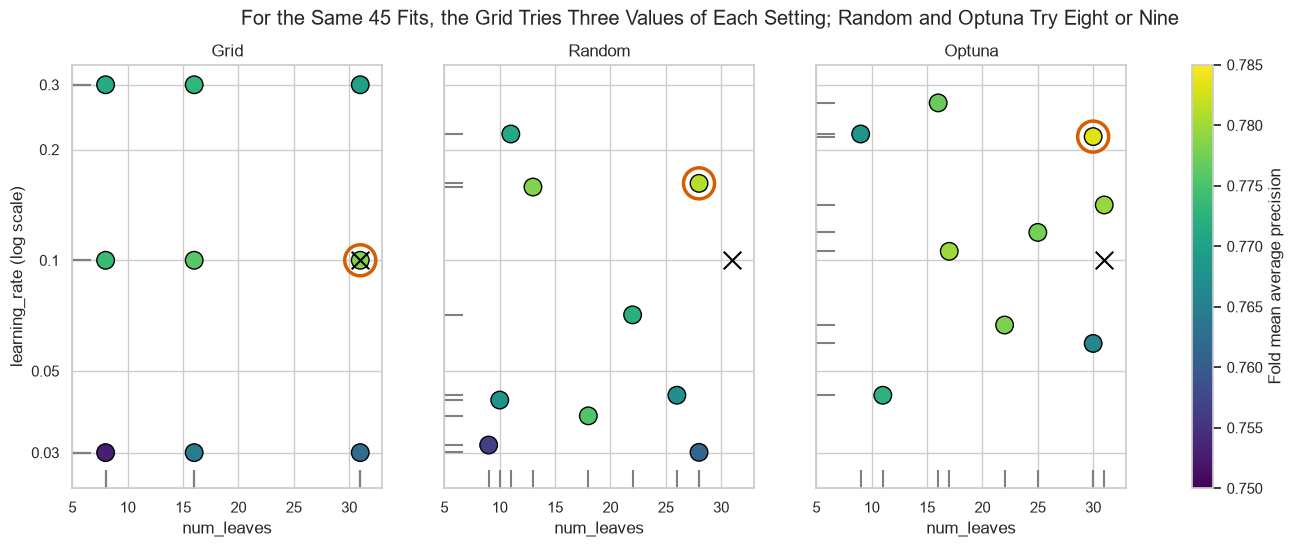

In [23]:
# the three searches side by side, on the same axes and one colour scale
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)
dots = panels(9, axes)
fig.colorbar(dots, ax=axes, label="Fold mean average precision")
fig.suptitle("For the Same 45 Fits, the Grid Tries Three Values of Each Setting; Random and Optuna Try Eight or Nine")
plt.show()

The grid tries three leaf counts and three rates; the random search and Optuna each try eight leaf counts and nine rates.

Optuna's guided trials lean toward many leaves, where its random start scored best.

The colours barely change: every candidate of the three searches scores between 0.75 and 0.79.

### Your Turn: Watch the Searches Unfold

Slide the candidates tried from 1 to 9 and watch each search fill its box.

In [24]:
# your turn: the three panels after the first few candidates of each search
def draw_searches(tried_up_to=4):
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)
    dots = panels(tried_up_to, axes)
    fig.colorbar(dots, ax=axes, label="Fold mean average precision")
    plt.show()

interact(draw_searches, tried_up_to=(1, 9));

interactive(children=(IntSlider(value=4, description='tried_up_to', max=9, min=1), Output()), _dom_classes=('w…

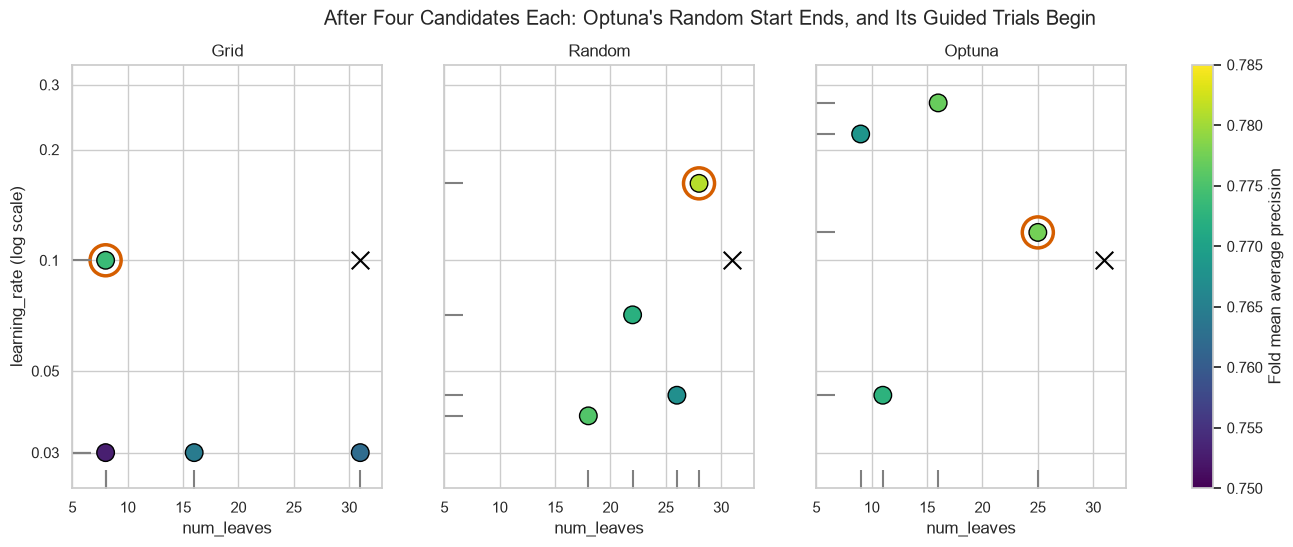

In [25]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)
dots = panels(4, axes)
fig.colorbar(dots, ax=axes, label="Fold mean average precision")
fig.suptitle("After Four Candidates Each: Optuna's Random Start Ends, and Its Guided Trials Begin")
plt.show()

**For the same budget, random and guided searches cover more values; all three bests sit within 0.005 of the defaults.**

# Reading the Searches

## The Search's Results Table

Course 4 read `cv_results_` for a grid; a randomized search keeps the same table.

In [26]:
# the random search's nine candidates: values, fold mean, fold standard deviation and rank
results = pd.DataFrame(search.cv_results_["params"])
results["mean"] = search.cv_results_["mean_test_score"]
results["fold sd"] = search.cv_results_["std_test_score"]
results["rank"] = search.cv_results_["rank_test_score"]
results

,learning_rate,num_leaves,mean,fold sd,rank
0,0.0711,22,0.7723,0.0598,4
1,0.1619,28,0.7811,0.0447,1
2,0.0430,26,0.7673,0.0546,7
3,0.0378,18,0.7755,0.0580,3
4,0.2204,11,0.7711,0.0536,5
5,0.0417,10,0.7681,0.0685,6
6,0.0315,9,0.7565,0.0649,9
7,0.1582,13,0.7785,0.0586,2
8,0.0301,28,0.7616,0.0531,8


In [27]:
# each candidate's five fold scores, then how far they spread against how far the nine means spread
fold_scores = pd.DataFrame({"fold " + str(k + 1): search.cv_results_["split" + str(k) + "_test_score"] for k in range(5)}, index=range(1, 10))
spans = fold_scores.max(axis=1) - fold_scores.min(axis=1)
print("The nine means span:", round(results["mean"].max() - results["mean"].min(), 4))
print("One candidate's five folds span:", round(spans.min(), 4), "to", round(spans.max(), 4))

The nine means span: 0.0246
One candidate's five folds span: 0.1209 to 0.1915


### Interpretation of the Scores

Each mean near 0.78 carries a fold sd near 0.05: the folds disagree.

One candidate's five folds span five to eight times what the nine means span.

So the gap between two candidates' means is small beside the noise in either.

## The Best So Far

`np.maximum.accumulate(values)` keeps, at each position, the largest value up to there: the **running best**.

In [28]:
# each search's running best, candidate by candidate
running = pd.DataFrame({name: np.maximum.accumulate(tried.loc[tried["search"] == name, "score"].to_numpy())
                        for name in ["Grid", "Random", "Optuna"]}, index=range(1, 10))
running

,Grid,Random,Optuna
1,0.7530,0.7723,0.7769
2,0.7644,0.7811,0.7775
3,0.7644,0.7811,0.7775
4,0.7737,0.7811,0.7775
5,0.7758,0.7811,0.7796
6,0.7783,0.7811,0.7796
7,0.7783,0.7811,0.7796
8,0.7783,0.7811,0.7832
9,0.7783,0.7811,0.7832


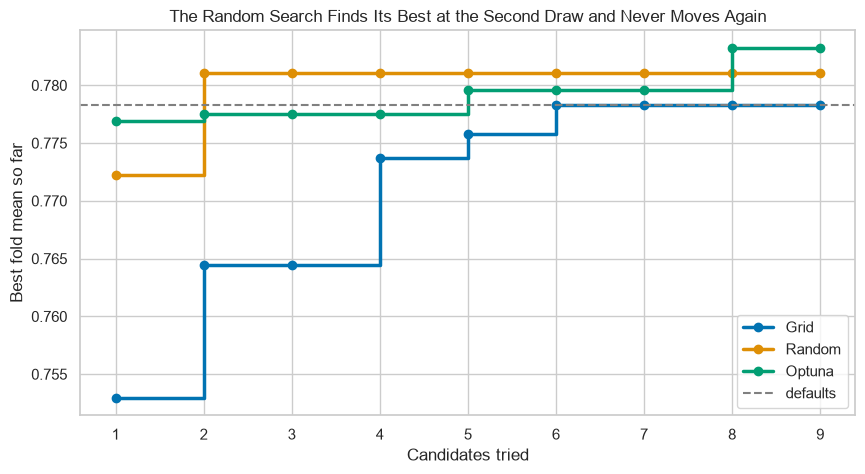

In [29]:
# the best so far against candidates tried, drawn as steps, the defaults dashed
for name in running:
    plt.plot(running.index, running[name], drawstyle="steps-post", linewidth=2.5, marker="o", label=name)
plt.axhline(default_scores.mean(), color="gray", linestyle="--", label="defaults")
plt.xticks(range(1, 10))
plt.xlabel("Candidates tried")
plt.ylabel("Best fold mean so far")
plt.title("The Random Search Finds Its Best at the Second Draw and Never Moves Again")
plt.legend(loc="lower right")
plt.show()

The random search reaches its best at its second draw.

Optuna climbs twice in its guided trials, and the grid reaches the defaults' cell at its sixth candidate.

After those steps every line is flat: more candidates bought nothing.

## Fold by Fold

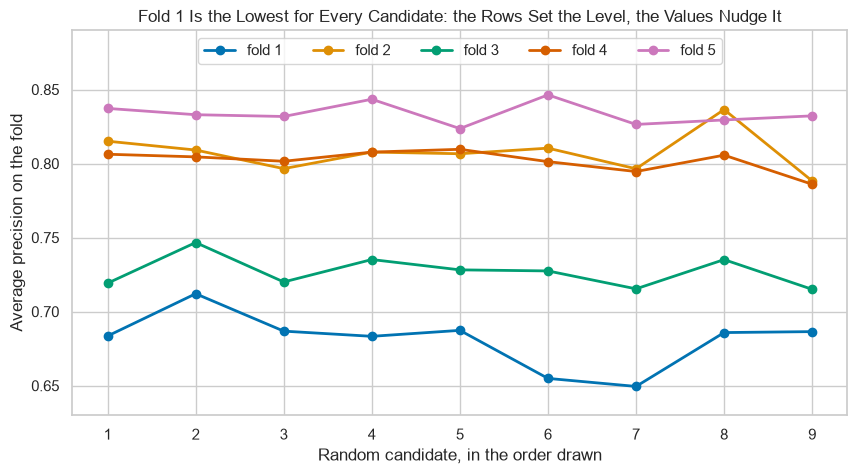

In [30]:
# each fold's score across the nine random candidates, one line per fold
for fold in fold_scores:
    plt.plot(fold_scores.index, fold_scores[fold], marker="o", linewidth=2, label=fold)
plt.xticks(range(1, 10))
plt.xlabel("Random candidate, in the order drawn")
plt.ylabel("Average precision on the fold")
plt.ylim(0.63, 0.89)
plt.title("Fold 1 Is the Lowest for Every Candidate: the Rows Set the Level, the Values Nudge It")
plt.legend(loc="upper center", ncol=5)
plt.show()

The lines run almost parallel: a fold that is hard for one candidate is hard for all of them.

Fold 1 sits lowest for every candidate.

**The rows in a fold set the level; the settings move it a little. Next we measure how far the folds alone move a score.**

# The Same Model on Other Folds

A fold split is one shuffle of the rows; another `random_state` gives another five folds of the same 4,680.

**Predict 3**

Q. The untuned defaults, scored on eight shuffles of the folds, `random_state=SEED + shift` for `shift` from 0 to 7. Write down the best of the eight means.

## Eight Shuffles of the Folds

In [31]:
# the same untuned model on eight different shuffles of the training rows into five folds
shuffled = {}
for shift in range(8):
    reshuffled = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + shift)
    shuffled[SEED + shift] = cross_val_score(default, X_train, y_train, cv=reshuffled, scoring="average_precision", n_jobs=1).mean()
shuffled = pd.Series(shuffled)
print("Eight means:", round(shuffled.min(), 4), "to", round(shuffled.max(), 4), " Best at seed", shuffled.idxmax())

Eight means: 0.7766 to 0.7939  Best at seed 47


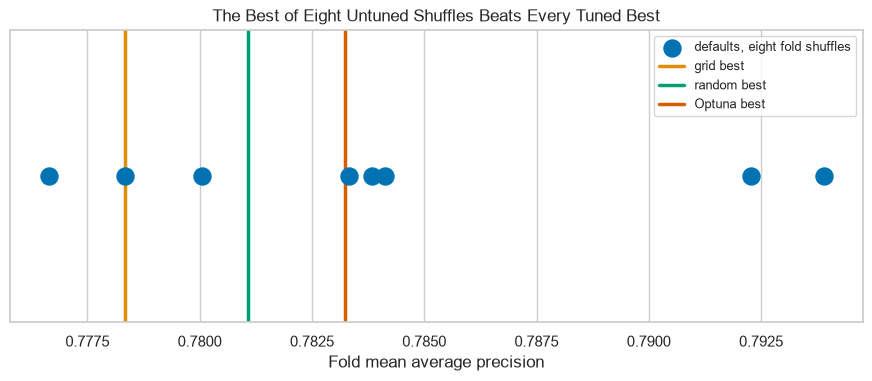

In [32]:
# the eight means as dots on one line, the three searches' bests as vertical lines
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.scatter(shuffled, [0] * 8, s=150, color="C0", zorder=3, label="defaults, eight fold shuffles")
bests = {"grid": grid.best_score_, "random": search.best_score_, "Optuna": study.best_value}
for colour, name in zip(["C1", "C2", "C3"], bests):
    ax.axvline(bests[name], color=colour, linewidth=2.5, label=name + " best")
ax.set(yticks=[], xlabel="Fold mean average precision")
ax.set_title("The Best of Eight Untuned Shuffles Beats Every Tuned Best")
ax.legend(loc="upper right", fontsize=9)
plt.show()

Nothing was tuned, yet the eight means run from 0.7766 to 0.7939, almost two hundredths apart.

The searches' lift over the defaults, 0.0027 and 0.0049, is under a third of that range.

Picking the best of many noisy numbers lifts the number with nothing changed: the **best-of-many lift**, also called the winner's curse.

**A search's `best_score_` is a best of nine, so it is not the chosen model's score. The fix is to score the search itself.**

# Nested Cross-Validation

![Nested cross-validation. The 4,680 training rows in five outer folds. For each outer fold, the four other folds, 3,744 rows, are cut into three inner folds, and the whole nine-candidate search runs on them: 9 candidates times 3 inner folds, 27 fits. The winner is refitted on the 3,744 rows, one fit, and scored once on the 936 rows of the outer fold it never saw. Five outer folds times 28 fits is 140 fits, and the nested score is the mean of the five outer scores.](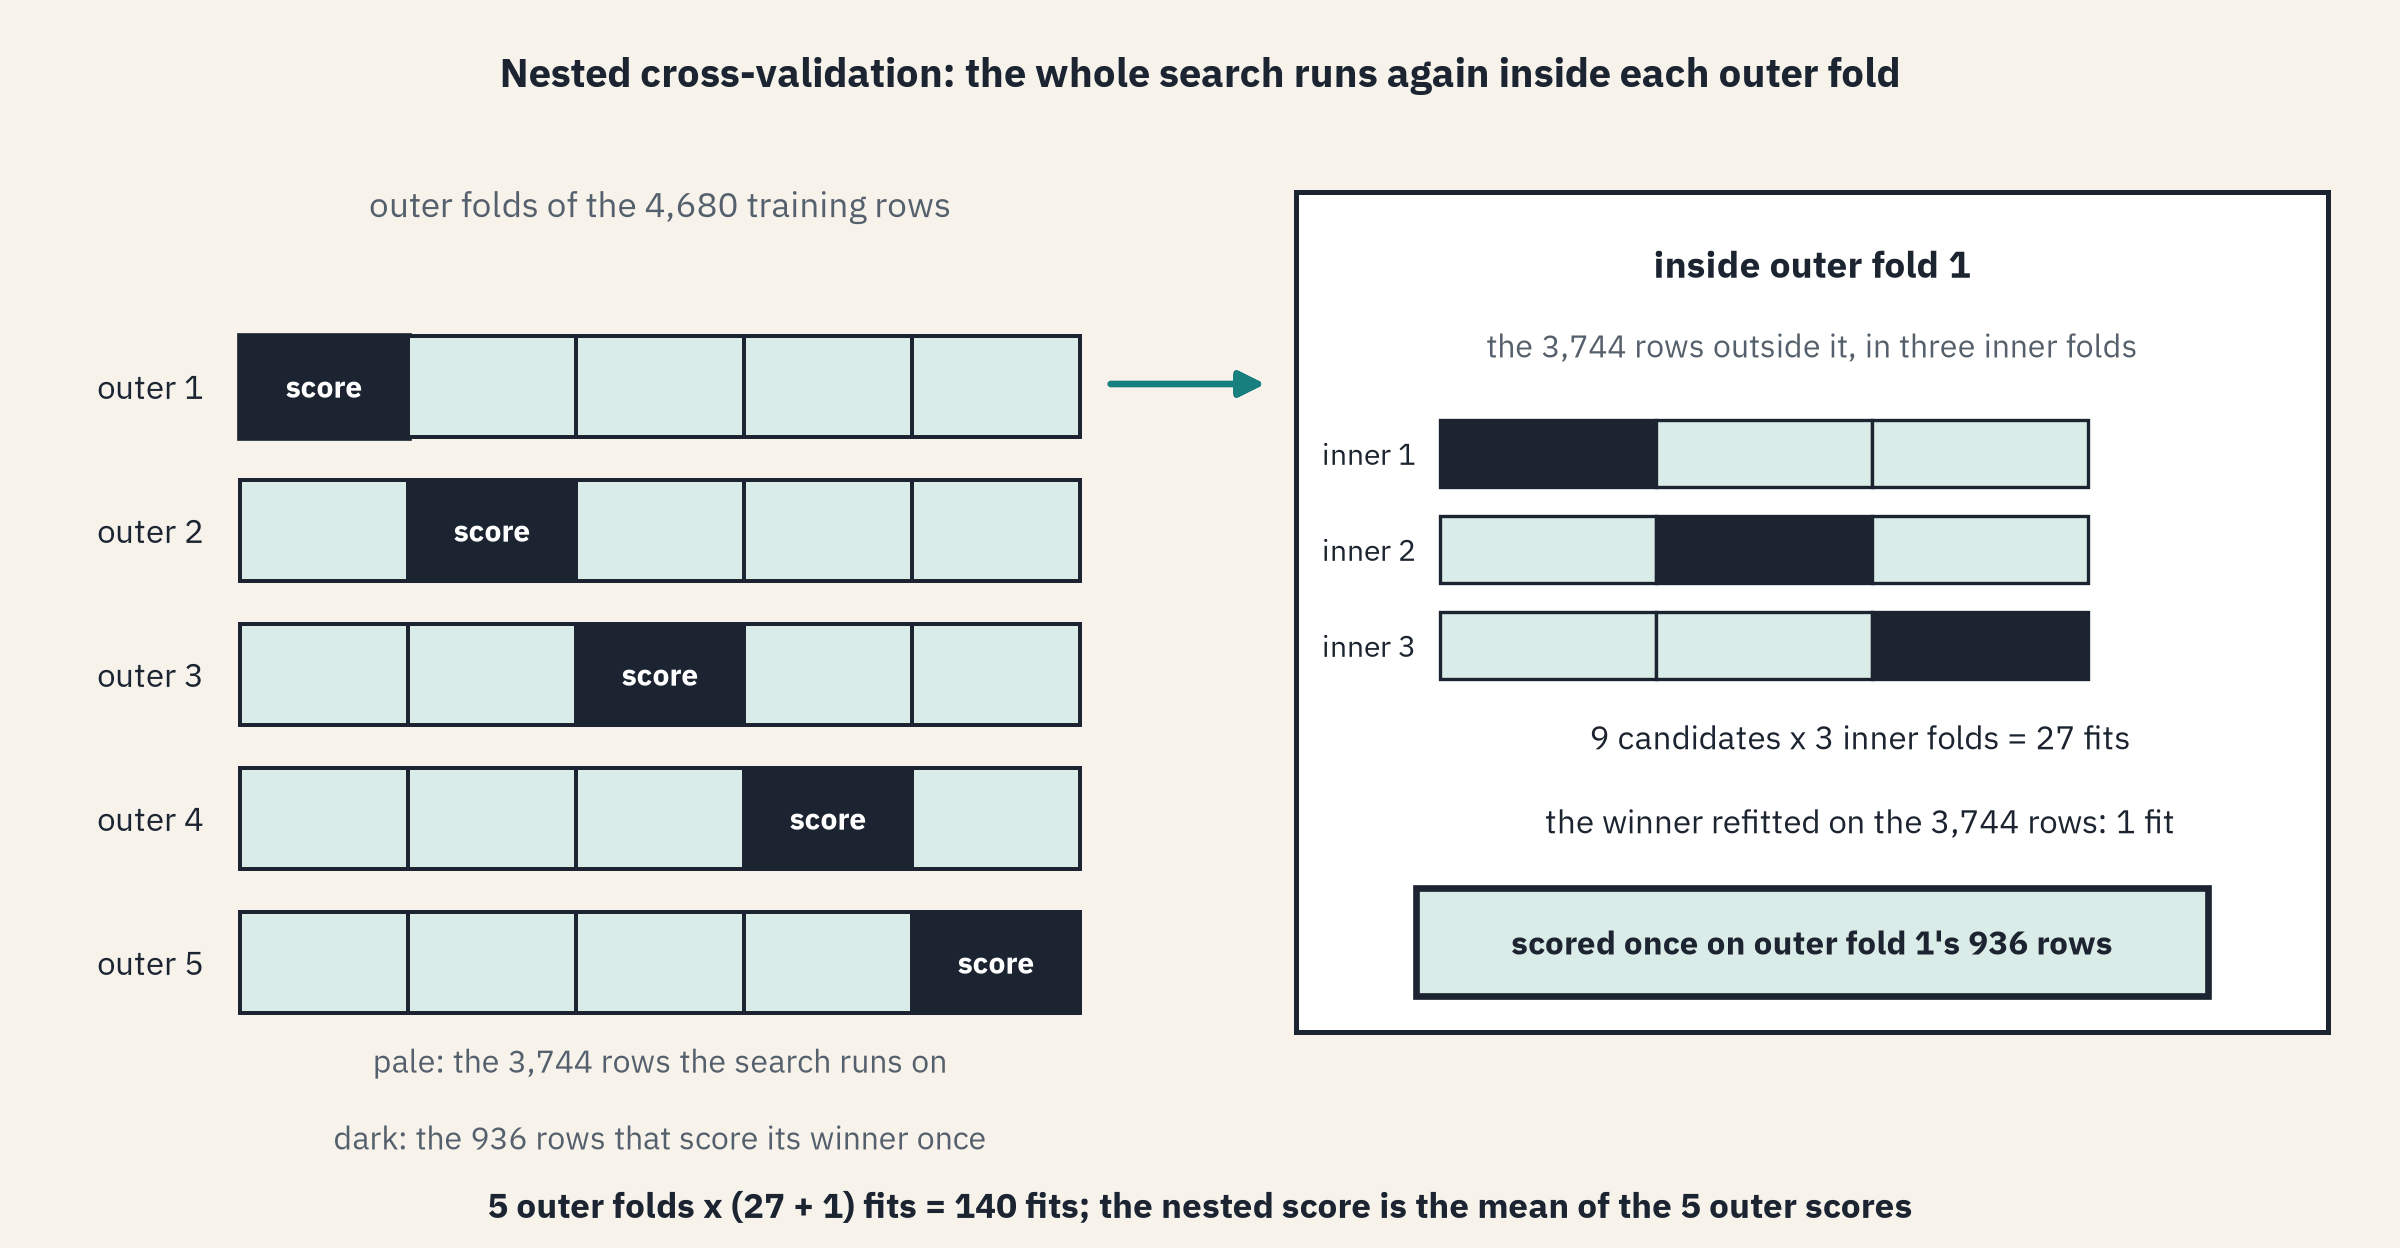)

**Nested cross-validation** scores a search, not a candidate.
The **outer folds** score; inside each outer training part, the **inner folds** run the whole search and choose a winner, which the outer fold then scores once.
Each outer fold's search never sees the rows it is scored on, so the mean is an **honest score** of the search.

**Predict 4**

The random search reported `best_score_` 0.7811.

Q. Score the same search by nested cross-validation. Write down its nested mean.

## The Search, Scored Honestly

`cross_validate` takes a search as it takes any model: each outer fold runs the search on the other four.

In [33]:
# the inner folds, and the random search on them: the same space, budget and seed
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
inner_search = RandomizedSearchCV(LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1), space, n_iter=9,
                                  cv=inner, scoring="average_precision", random_state=SEED, n_jobs=1)

# the outer folds are today's five; each outer fold keeps its search, so we can read what it chose
nested = cross_validate(inner_search, X_train, y_train, cv=folds, scoring="average_precision", return_estimator=True, n_jobs=1)
print("Outer folds:", nested["test_score"].round(4))
print("Nested mean:", round(nested["test_score"].mean(), 4), " best_score_:", round(search.best_score_, 4), " Defaults:", round(default_scores.mean(), 4))

Outer folds: [0.6873 0.8364 0.7192 0.8057 0.8372]
Nested mean: 0.7772  best_score_: 0.7811  Defaults: 0.7783


The nested mean sits below `best_score_` and below the untuned defaults.

`best_score_` leaned high, as Day 10 said it would; this is by how much on this file.

## Five Outer Folds, Three Winners

In [34]:
# each outer fold's winner, its inner best, its outer score, and the defaults on the same outer fold
winners = pd.DataFrame([searched.best_params_ for searched in nested["estimator"]], index=range(1, 6))
winners["inner best"] = [searched.best_score_ for searched in nested["estimator"]]
winners["outer fold"] = nested["test_score"]
winners["defaults"] = default_scores
winners

,learning_rate,num_leaves,inner best,outer fold,defaults
1,0.2204,11,0.7860,0.6873,0.7077
2,0.1582,13,0.7750,0.8364,0.7988
3,0.0711,22,0.7706,0.7192,0.7434
4,0.1582,13,0.7561,0.8057,0.8013
5,0.0711,22,0.7252,0.8372,0.8405


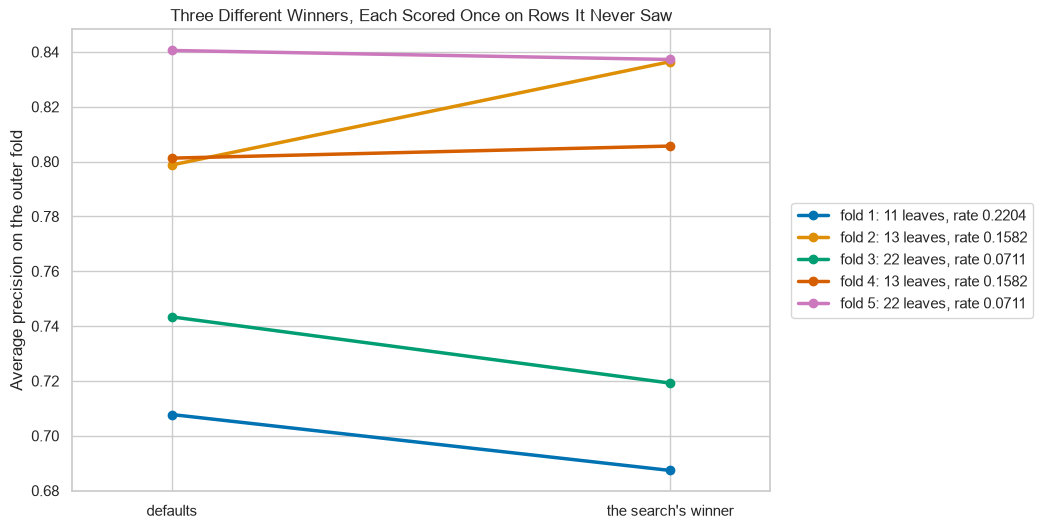

In [35]:
# one line per outer fold: the defaults on the left, the search's winner on the right, labelled with its values
plt.figure(figsize=(9, 6))
for fold, row in winners.iterrows():
    plt.plot([0, 1], [row["defaults"], row["outer fold"]], marker="o", linewidth=2.5,
             label=f"fold {fold}: {row['num_leaves']:.0f} leaves, rate {row['learning_rate']:.4f}")
plt.xticks([0, 1], ["defaults", "the search's winner"])
plt.xlim(-0.2, 1.2)
plt.ylabel("Average precision on the outer fold")
plt.title("Three Different Winners, Each Scored Once on Rows It Never Saw")
plt.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

Every outer search drew the same nine candidates, and chose three different winners across the five.

The winner beats the defaults on outer folds 2 and 4 and trails them on the other three.

Fold 1 stays the hardest fold, whichever model is scored on it.

**Scored honestly, the search does not beat the defaults on this file; its winner depends on which rows chose it.**

# Final Model Selection

## Every Score on One Line

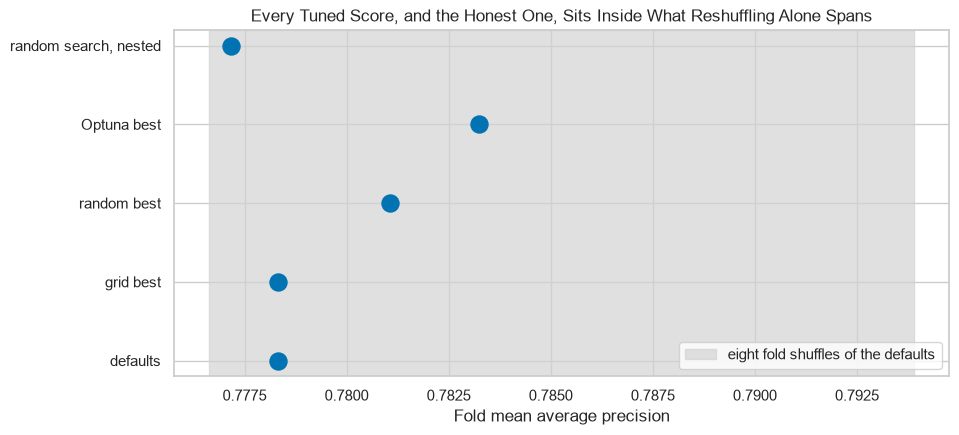

In [36]:
# every score of the day, over the band the eight shuffles of the untuned model spanned
board = pd.Series({"defaults": default_scores.mean(), "grid best": grid.best_score_, "random best": search.best_score_,
                   "Optuna best": study.best_value, "random search, nested": nested["test_score"].mean()})
plt.figure(figsize=(10, 4.5))
plt.axvspan(shuffled.min(), shuffled.max(), color="lightgray", alpha=0.7, label="eight fold shuffles of the defaults")
plt.scatter(board, board.index, s=150, zorder=3)
plt.xlabel("Fold mean average precision")
plt.title("Every Tuned Score, and the Honest One, Sits Inside What Reshuffling Alone Spans")
plt.legend(loc="lower right")
plt.show()

Three bests, the defaults and the nested score all land inside the band.

Only the nested score answers the colleague's third question.

## The Threshold Is Tuned Too

Day 10 chose each threshold for a recall of 0.70 from out-of-fold probabilities on the training rows, with `cross_val_predict` and the largest threshold that keeps recall at 0.70.
The same rule here, for the defaults and the random search's winner.

In [37]:
# each training company's out-of-fold probability, then the largest threshold that keeps recall at 0.70
rows = []
for model in [default, search.best_estimator_]:
    out_of_fold = cross_val_predict(model, X_train, y_train, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_train, out_of_fold)
    threshold = thresholds[recall[:-1] >= 0.70].max()
    flagged = out_of_fold >= threshold
    rows.append([threshold, flagged.sum(), (flagged & (y_train == 1)).sum(), precision_score(y_train, flagged)])
thresholds_70 = pd.DataFrame(rows, columns=["threshold", "flagged", "caught", "precision"], index=["defaults", "random winner"])
thresholds_70

,threshold,flagged,caught,precision
defaults,0.0818,327,229,0.7003
random winner,0.0333,332,229,0.6898


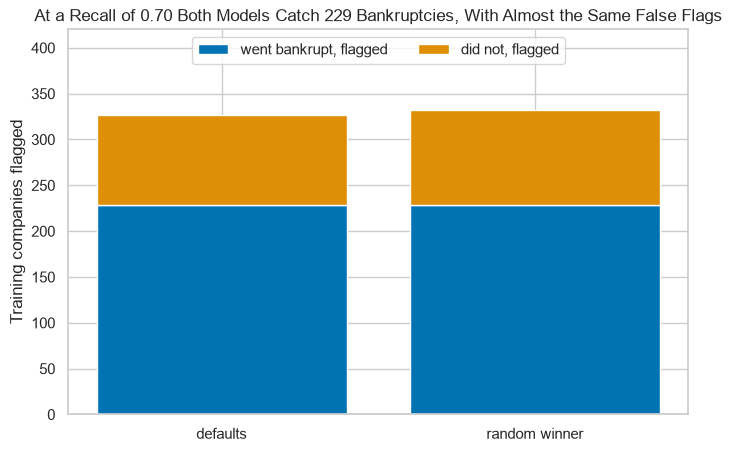

In [38]:
# caught and false flags at each model's threshold, stacked
plt.figure(figsize=(8, 5))
plt.bar(thresholds_70.index, thresholds_70["caught"], label="went bankrupt, flagged")
plt.bar(thresholds_70.index, thresholds_70["flagged"] - thresholds_70["caught"], bottom=thresholds_70["caught"], label="did not, flagged")
plt.ylim(0, 420)
plt.ylabel("Training companies flagged")
plt.title("At a Recall of 0.70 Both Models Catch 229 Bankruptcies, With Almost the Same False Flags")
plt.legend(loc="upper center", ncol=2)
plt.show()

The thresholds differ, 0.0818 and 0.0333, because the two models spread their probabilities differently.

At them both catch 229 of the 326 bankruptcies, and the defaults flag 5 fewer companies.

A threshold is a setting like any other, chosen here on the training rows' out-of-fold probabilities.

**The defaults go forward to Day 12: the honest score gives no reason to pay for the search, and the threshold is chosen on out-of-fold probabilities like every other setting.**

# Insights and Conclusion

LightGBM at its defaults beats Course 4's choice on every fold, 0.7783 against 0.6624.

Three searches of nine candidates found bests 0.0000 to 0.0049 above the defaults, inside one fold sd and under a third of what reshuffling the folds alone spans.

Nested cross-validation scores the random search at 0.7772, below its `best_score_` and the defaults.

In practice: fix the budget and the folds before looking, search a rate on a log scale, stop when the running best is flat, and report the nested score beside `best_score_`.

**Tuning is a choice made on rows: score the choice, not its best number.**

> STORY: James Bergstra and Yoshua Bengio published "Random Search for Hyper-Parameter Optimization" in the Journal of Machine Learning Research, volume 13, pages 281 to 305, in 2012. This note gives the paper's bibliography only. Source: https://jmlr.org/papers/v13/bergstra12a.html

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Count what a grid of settings costs, and fix a search's budget before it runs.
* Search a space with `RandomizedSearchCV` and `scipy.stats` distributions, and with an Optuna study.
* Read `cv_results_` fold by fold, and draw a search's running best.
* Measure how far reshuffling the folds moves a score.
* Score a search with nested cross-validation, and choose a threshold after it.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [39]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**A Smaller Budget**

Q. Run the random search with `n_iter=4` on the same space, folds and seed. Store its best fold mean in `ex1_best`.

In [40]:
# the same search on four candidates: the first four draws of the nine
search_4 = RandomizedSearchCV(LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1), space, n_iter=4,
                              cv=folds, scoring="average_precision", random_state=SEED, n_jobs=1).fit(X_train, y_train)
ex1_best = search_4.best_score_
print("Best:", search_4.best_params_["num_leaves"], "leaves, rate", round(search_4.best_params_["learning_rate"], 4), " Mean:", round(ex1_best, 4))

Best: 28 leaves, rate 0.1619  Mean: 0.7811


The same seed draws the same first four candidates, and the nine's best was its second draw, so four find it too.

In [41]:
check("Exercise 1 the best of four", ex1_best, 0.7810671480904319)

Exercise 1 the best of four: correct


### Exercise 2

**Tune XGBoost Instead**

Q. Search Day 8's `XGBClassifier(random_state=SEED, n_jobs=1)` with `max_depth` from `randint(2, 7)` and `learning_rate` from `loguniform(0.03, 0.3)`, `n_iter=4`, on the same folds, scoring average precision, with `random_state=SEED`. Store its best fold mean, through `float(...)`, in `ex2_best`.

In [42]:
# Day 8's booster, searched on its depth and its rate
from xgboost import XGBClassifier
xgb_space = {"max_depth": randint(2, 7), "learning_rate": loguniform(0.03, 0.3)}
xgb_search = RandomizedSearchCV(XGBClassifier(random_state=SEED, n_jobs=1), xgb_space, n_iter=4,
                                cv=folds, scoring="average_precision", random_state=SEED, n_jobs=1).fit(X_train, y_train)
ex2_best = float(xgb_search.best_score_)
print("Best: depth", xgb_search.best_params_["max_depth"], " rate", round(xgb_search.best_params_["learning_rate"], 4), " Mean:", round(ex2_best, 4))

Best: depth 3  rate 0.1186  Mean: 0.7691


In [43]:
check("Exercise 2 XGBoost's best", ex2_best, 0.7690961431171907)

Exercise 2 XGBoost's best: correct


### Exercise 3

**A Third Setting**

Q. Add `min_child_samples` from `randint(5, 60)` to the space and search with `n_iter=6`. Store the best fold mean in `ex3_best`, and in `ex3_beyond_sd` whether its gain over the defaults' mean is larger than the defaults' fold sd (`True` or `False`).

In [44]:
# a third setting in the space, six candidates
space_3 = {"num_leaves": randint(8, 32), "learning_rate": loguniform(0.03, 0.3), "min_child_samples": randint(5, 60)}
search_3 = RandomizedSearchCV(LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1), space_3, n_iter=6,
                              cv=folds, scoring="average_precision", random_state=SEED, n_jobs=1).fit(X_train, y_train)

# the gain over the defaults, against the defaults' fold sd
ex3_best = search_3.best_score_
ex3_beyond_sd = bool(ex3_best - default_scores.mean() > default_scores.std())
print("Best:", round(ex3_best, 4), " Gain:", round(ex3_best - default_scores.mean(), 4), " Fold sd:", round(default_scores.std(), 4))
print("Is the gain larger than one fold sd?", ex3_beyond_sd)

Best: 0.7817  Gain: 0.0034  Fold sd: 0.0469
Is the gain larger than one fold sd? False


In [45]:
check("Exercise 3 the best of six", ex3_best, 0.781689963770517)
check("Exercise 3 beyond one fold sd", ex3_beyond_sd, False)

Exercise 3 the best of six: correct
Exercise 3 beyond one fold sd: correct


### Exercise 4: AI check

**The Score in the Model Log**

You asked an AI assistant for a cell that writes the tuned model's cross-validated score into the desk's model log.
This came back.
It runs.
Test it, then find the one bug.

In [46]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
# the tuned model's settings and its cross-validated score, for the model log
report = {"model": "LightGBM, randomized search", "num_leaves": search.best_params_["num_leaves"],
          "cross-validated score": round(search.best_score_, 4)}
for key, value in report.items():
    print(key + ":", value)

model: LightGBM, randomized search
num_leaves: 28
cross-validated score: 0.7811


In [47]:
# the test: the tuned model's score is the search scored on rows it never chose on, the nested mean
assert report["cross-validated score"] == round(nested["test_score"].mean(), 4), "best_score_ reported: the best of nine on the rows that chose it"

AssertionError: best_score_ reported: the best of nine on the rows that chose it

Q. Fix the report, and store the score it should carry, unrounded, in `ex4_score`.

In [48]:
# the fix: best_score_ is the best of nine on the rows that chose it; the search's own score is the nested mean
report = {"model": "LightGBM, randomized search", "num_leaves": search.best_params_["num_leaves"],
          "cross-validated score": round(nested["test_score"].mean(), 4)}
assert report["cross-validated score"] == round(nested["test_score"].mean(), 4)
ex4_score = nested["test_score"].mean()
for key, value in report.items():
    print(key + ":", value)

model: LightGBM, randomized search
num_leaves: 28
cross-validated score: 0.7772


In [49]:
check("Exercise 4 the honest score", ex4_score, 0.7771767580388683)

Exercise 4 the honest score: correct


## Congratulations!

You took Course 4's chosen model, beat it by more than a tenth with an untuned booster, and then asked whether tuning helps.
You spent one budget three ways, a grid, a random search and a guided Optuna study, and watched where each one looked.
You saw that reshuffling the folds moves a score more than any search did, and you scored a search honestly from the outside.
That habit, scoring the choice rather than its best number, is what makes a tuned model believable.
In Day 12 you take the defaults forward and build new columns from the ratios, scoring each one against the same fold noise.

[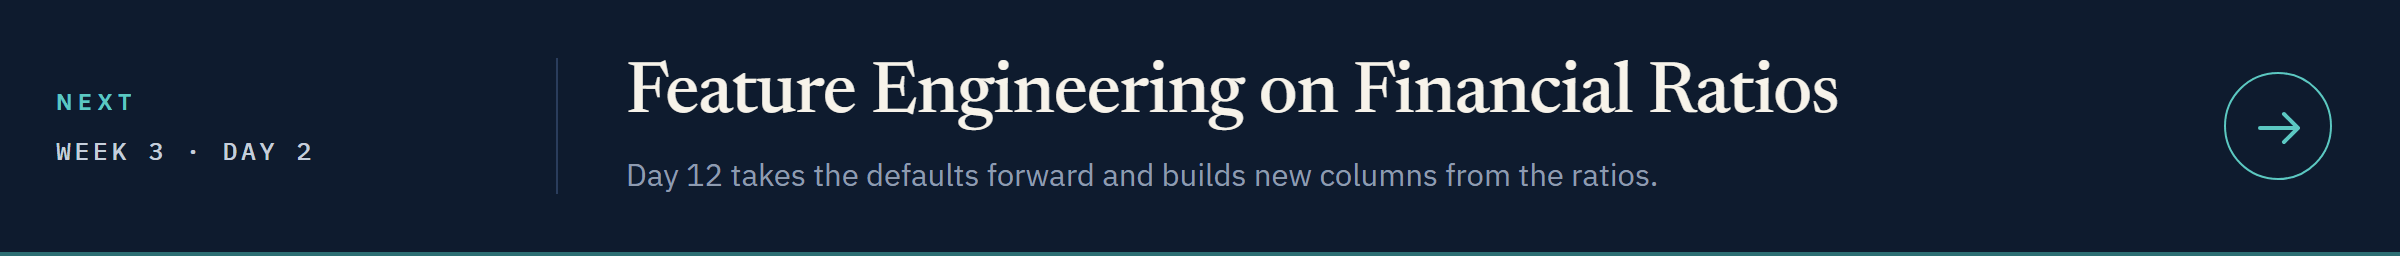](../day2/12_feature_engineering_on_financial_ratios.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week3/day2/12_feature_engineering_on_financial_ratios.ipynb)